# Daily Challenge — Logistic Regression for Admission Prediction

This exercise uses two exam scores to model the admission labels in a teaching dataset. Run the notebook from top to bottom in Jupyter or Colab. It uses the accompanying text file when present and downloads a copy from the course's linked repository otherwise.

In [1]:
# Step 1. Read the headerless file and give each of the three columns a name.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

local_data = Path("Admission Exam Scores.txt")
remote_data = "https://raw.githubusercontent.com/kaleko/CourseraML/master/ex2/data/ex2data1.txt"
features = ["exam_1", "exam_2"]
data = pd.read_csv(local_data if local_data.exists() else remote_data,
                   header=None, names=[*features, "admitted"])

# Check the first five rows, the class balance, and whether any values are missing.
print(data.head().to_string(index=False))
print(f"Rows: {len(data)} | Missing values: {data.isna().sum().sum()}")
print(data["admitted"].value_counts().sort_index().rename(index={0: "Not admitted", 1: "Admitted"}))

   exam_1    exam_2  admitted
34.623660 78.024693         0
30.286711 43.894998         0
35.847409 72.902198         0
60.182599 86.308552         1
79.032736 75.344376         1
Rows: 100 | Missing values: 0
admitted
Not admitted    40
Admitted        60
Name: count, dtype: int64


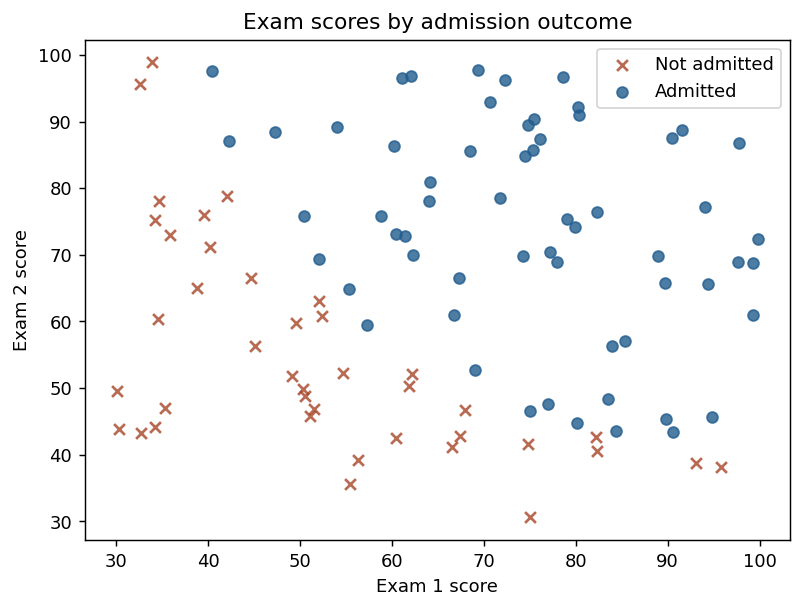

In [2]:
# Step 2. Plot the two scores, using the known label to choose a marker and color.
fig, ax = plt.subplots(figsize=(7, 5))
for label, description, marker, color in [
    (0, "Not admitted", "x", "#a74627"),
    (1, "Admitted", "o", "#225d8e"),
]:
    group = data.loc[data["admitted"].eq(label)]
    ax.scatter(group["exam_1"], group["exam_2"], marker=marker, color=color,
               label=description, alpha=0.8)
ax.set(xlabel="Exam 1 score", ylabel="Exam 2 score", title="Exam scores by admission outcome")
ax.legend()
plt.show()

The admitted points generally have higher scores, but the two groups overlap. A logistic regression model combines the scores and estimates the probability of the positive class. With two input features, its 0.50 probability cutoff forms a straight line in the scatter plot.

In [3]:
# Step 3. Split the data before scaling or fitting so we can evaluate unseen rows.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = data[features]
y = data["admitted"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Stratification preserves the class ratio. The scaler learns each exam's
# mean and standard deviation from the training rows during fit().
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# Convert the fitted coefficients back to the original exam-score units.
# This makes the formula readable without manually standardizing a score.
scaler = model.named_steps["standardscaler"]
classifier = model.named_steps["logisticregression"]
weights = classifier.coef_[0] / scaler.scale_
intercept = classifier.intercept_[0] - weights @ scaler.mean_
print(f"log-odds of admission = {intercept:.4f} + {weights[0]:.4f} × Exam 1 + {weights[1]:.4f} × Exam 2")

log-odds of admission = -12.8160 + 0.1069 × Exam 1 + 0.1015 × Exam 2


In [4]:
# Step 4. Predict labels and positive-class probabilities on held-out rows.
# predict() classifies using the standard 0.50 probability cutoff.
prediction = model.predict(X_test)
probability = model.predict_proba(X_test)[:, 1]
example = X_test.assign(actual=y_test, predicted=prediction, probability=probability)
print(example.head().round(3).to_string(index=False))

# Compare the fraction of correct predictions with a majority-class baseline.
train_accuracy = model.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, prediction)
majority_label = y_train.mode().iat[0]
baseline = y_test.eq(majority_label).mean()
tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
print(f"Training accuracy: {train_accuracy:.1%} ({len(y_train)} samples)")
print(f"Test accuracy: {test_accuracy:.1%} ({len(y_test)} samples)")
print(f"Test accuracy from always predicting the training majority class: {baseline:.1%}")
print(f"Test confusion counts: {tn} true negatives, {fp} false positives, "
      f"{fn} false negatives, {tp} true positives")

 exam_1  exam_2  actual  predicted  probability
 74.776  89.530       1          1        0.986
 62.073  96.769       1          1        0.974
 79.033  75.344       1          1        0.964
 85.405  57.052       1          1        0.891
 52.108  63.128       0          0        0.302
Training accuracy: 87.5% (80 samples)
Test accuracy: 95.0% (20 samples)
Test accuracy from always predicting the training majority class: 60.0%
Test confusion counts: 8 true negatives, 0 false positives, 1 false negatives, 11 true positives


## Step 5 — Interpret the results

Both fitted coefficients are positive. Holding one exam score fixed, a higher score on the other exam raises the estimated probability of admission. The coefficients describe an association in this dataset.

The model got **19 out of 20** test cases right (**95% accuracy**). Always predicting the training set's majority class would get **60%** right. The model incorrectly predicted admission for 0 test example(s) and missed 1 admitted example(s). With only 20 test rows, each additional error changes accuracy by 5%, so the estimate can vary across splits.